In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Path mengarah ke data bersih di folder processed
DATA_CLEAN_PATH = "../data/processed/wikipedia_clean.parquet"

# Load LazyFrame menggunakan Polars
df = pl.scan_parquet(DATA_CLEAN_PATH)
print("Data berhasil dimuat!")

Data berhasil dimuat!


In [2]:
# Menambahkan kolom jumlah karakter dan estimasi jumlah kata
df_stats = df.with_columns([
    pl.col("text").str.len_chars().alias("char_count"),
    pl.col("text").str.split(" ").list.len().alias("word_count")
])

# Ambil ringkasan statistik (Mean, Median, Max, Min)
summary_stats = df_stats.select([
    pl.col("word_count").mean().alias("avg_words"),
    pl.col("word_count").median().alias("median_words"),
    pl.col("word_count").max().alias("max_words"),
    pl.col("word_count").min().alias("min_words"),
]).collect()

print("Statistik Jumlah Kata per Artikel Wikipedia:")
print(summary_stats)

Statistik Jumlah Kata per Artikel Wikipedia:
shape: (1, 4)
┌───────────┬──────────────┬───────────┬───────────┐
│ avg_words ┆ median_words ┆ max_words ┆ min_words │
│ ---       ┆ ---          ┆ ---       ┆ ---       │
│ f64       ┆ f64          ┆ u32       ┆ u32       │
╞═══════════╪══════════════╪═══════════╪═══════════╡
│ 45.941    ┆ 33.0         ┆ 4462      ┆ 1         │
└───────────┴──────────────┴───────────┴───────────┘


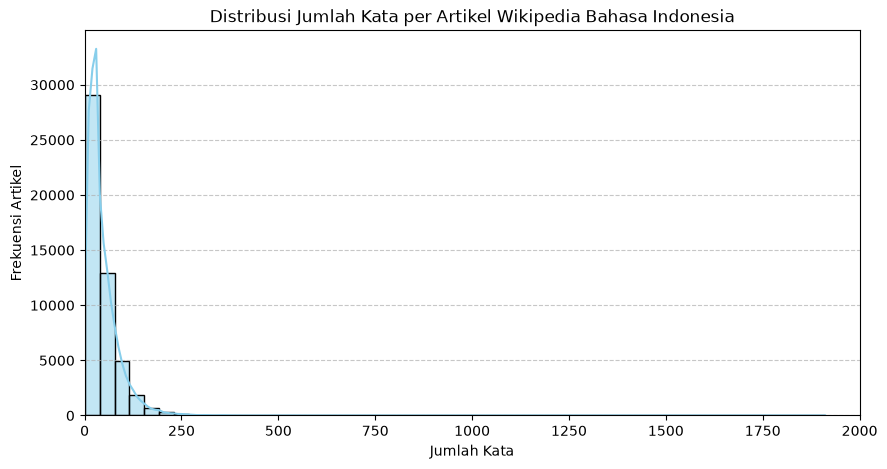

In [4]:
# mengambil sampel 50.000 data untuk visualisasi agar proses plot cepat
sample_words = df_stats.select("word_count").head(50_000).collect()["word_count"].to_list()

plt.figure(figsize=(10, 5))
sns.histplot(sample_words, bins=50, kde=True, color="skyblue")
plt.title("Distribusi Jumlah Kata per Artikel Wikipedia Bahasa Indonesia")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi Artikel")
plt.xlim(0, 2000) # Batasi rentang sumbu X agar grafik terfokus
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [5]:
# Top 5 Artikel Terpanjang
top_longest = df_stats.sort("word_count", descending=True).select(["title", "word_count"]).head(5).collect()

print("Top 5 Artikel Wikipedia Terpanjang:")
print(top_longest)

Top 5 Artikel Wikipedia Terpanjang:
shape: (5, 2)
┌─────────────────────────────────┬────────────┐
│ title                           ┆ word_count │
│ ---                             ┆ ---        │
│ str                             ┆ u32        │
╞═════════════════════════════════╪════════════╡
│ Surat Berharga Syariah Negara   ┆ 4462       │
│ Corey Haim                      ┆ 2979       │
│ Aksara di Warcraft              ┆ 2348       │
│ Dorabase                        ┆ 2268       │
│ Daftar karakter Hunter × Hunte… ┆ 1970       │
└─────────────────────────────────┴────────────┘


10 Kata Paling Sering Muncul pada Judul Artikel:
shape: (10, 2)
┌─────────────┬───────┐
│ title       ┆ count │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ daftar      ┆ 18626 │
│ indonesia   ┆ 16930 │
│ dari        ┆ 14212 │
│ negeri      ┆ 13833 │
│ kota        ┆ 8921  │
│ kabupaten   ┆ 8880  │
│ universitas ┆ 8076  │
│ (film)      ┆ 7087  │
│ nasional    ┆ 6998  │
│ bahasa      ┆ 6516  │
└─────────────┴───────┘


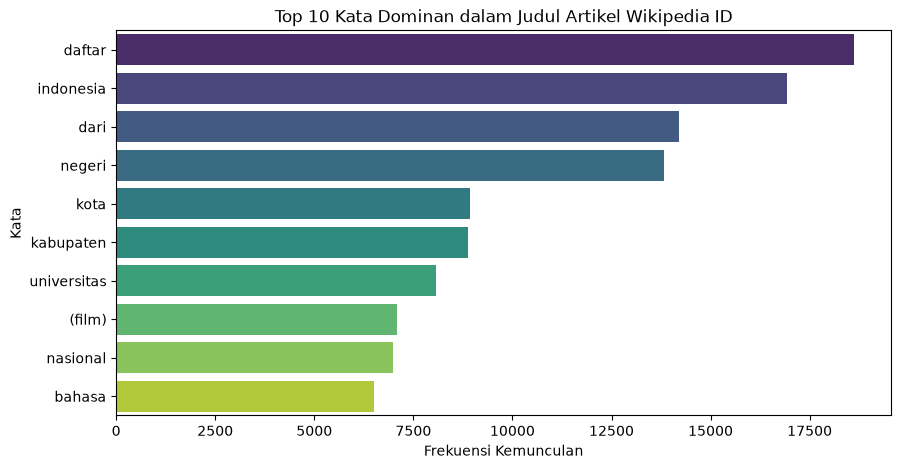

In [8]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Ekstrak kata-kata dari judul dan hitung frekuensinya
title_words = (
    df.select(pl.col("title").str.to_lowercase().str.split(" "))
    .explode("title")
    .filter(pl.col("title").str.len_chars() > 3)
    .group_by("title")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
    .head(10)
    .collect()
)

print("10 Kata Paling Sering Muncul pada Judul Artikel:")
print(title_words)

# Visualisasi Bar Chart (Bebas Warning)
plt.figure(figsize=(10, 5))
sns.barplot(
    x="count", 
    y="title", 
    data=title_words.to_pandas(), 
    hue="title", 
    palette="viridis", 
    legend=False
)
plt.title("Top 10 Kata Dominan dalam Judul Artikel Wikipedia ID")
plt.xlabel("Frekuensi Kemunculan")
plt.ylabel("Kata")
plt.show()